
## Задача 1. Плей-офф НХЛ 2025/2026: анализ записей событий матчей




In [1]:
import numpy as np                          # численные операции: массивы, NaN, векторные вычисления
import pandas as pd                         # таблицы (DataFrame) и чтение Excel
import matplotlib.pyplot as plt             # базовая библиотека для графиков
import seaborn as sns                       # статистические графики поверх matplotlib
from matplotlib.ticker import MaxNLocator   # позволяет сделать на оси только целые деления

pd.set_option('display.width', 140)         # ширина вывода таблиц в символах (чтобы не переносились столбцы)
sns.set_theme(style='whitegrid', context='notebook')   # единый стиль графиков: светлый фон с сеткой
plt.rcParams['figure.dpi'] = 110            # чёткость графиков в ноутбуке

## Задание 1. Чтение данных

Читаем таблицу функцией `pd.read_excel`. В файле первым столбцом идёт безымянный столбец с номерами строк (`Unnamed: 0`): он дублирует обычный индекс pandas и не несёт информации, поэтому его удаляем. После этого размер таблицы совпадает с примером из задания: `(29710, 38)`.

In [ ]:

events = pd.read_excel('NHL-playoffs-2026.xlsx')
# Первый столбец 'Unnamed: 0' — номера строк из Excel, удаляем.
# errors='ignore' — не падать с ошибкой, если такого столбца вдруг нет.
events = events.drop(columns='Unnamed: 0', errors='ignore')

# Проверка: размер таблицы должен совпасть с примером из задания (29710 строк, 38 столбцов)
assert events.shape == (29710, 38), events.shape

In [3]:
events.shape        # (число строк, число столбцов)

(29710, 38)

In [ ]:

events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Небольшой обзор данных: сколько в таблице игр, за какой период и какие типы событий есть.

In [ ]:
# Сколько всего разных игр и событий в таблице, за какой период, и сколько событий каждого типа
print('Игр:', events['Game ID'].nunique(), '| событий:', len(events))
print('Период дат:', events['Date'].min(), '—', events['Date'].max())     # даты в формате YYYY-MM-DD сортируются как строки
events['Play Type'].value_counts()                                           

Игр: 82 | событий: 29710
Период дат: 2026-04-18 — 2026-06-14


Play Type
hit                5621
faceoff            4995
shot-on-goal       4137
stoppage           3958
blocked-shot       2798
missed-shot        2643
giveaway           2604
penalty             804
takeaway            779
goal                486
period-start        272
period-end          272
delayed-penalty     259
game-end             82
Name: count, dtype: int64

В таблице есть пропуски (`NaN`), и они осмысленны: у служебных событий нет зоны, координат или команды, поэтому пропуски это не ошибки, их не нужно заполнять.

In [6]:
# У каких типов событий не заполнена зона (Play Zone) — это служебные события без места на площадке
events.loc[events['Play Zone'].isna(), 'Play Type'].value_counts()

Play Type
stoppage           3958
period-start        272
period-end          272
delayed-penalty     259
game-end             82
Name: count, dtype: int64

## Задание 2. Сводная таблица по играм

Строим таблицу `games` (индекс — `Game ID`) со столбцами `Date`, `Away Team`, `Home Team`, `Away Score`, `Home Score`, `Outcome`.

* **Итоговый счёт** берём из последнего события каждой игры — `game-end`: поля `Cumulated Away Score` и `Cumulated Home Score`.
* **Овертаймы** определяем по номеру периода, в котором закончилась игра: если период 3, то основное время (`Final`), 4 — один овертайм (`Final/OT`), 5 — два овертайма (`Final/2OT`).



In [ ]:
# Одна строка game-end на игру содержит итоговый счёт и номер последнего периода
game_end = events[events['Play Type'] == 'game-end'].set_index('Game ID')
# Проверка: Game ID не повторяется, и game-end есть у каждой игры
assert game_end.index.is_unique and len(game_end) == events['Game ID'].nunique()


def outcome(last_period):
    """Исход игры по номеру последнего периода: Final, Final/OT, Final/2OT, ..."""
    n_ot = last_period - 3             # число овертаймов: периоды после третьего
    if n_ot <= 0:
        return 'Final'                 # игра закончилась в основное время
    return 'Final/OT' if n_ot == 1 else f'Final/{n_ot}OT'


# Собираем таблицу games: один ряд = одна игра, индекс — Game ID
games = pd.DataFrame({
    'Date': game_end['Date'],
    'Away Team': game_end['Away Team'],
    'Home Team': game_end['Home Team'],
    'Away Score': game_end['Cumulated Away Score'],     # накопленный счёт на момент game-end = итоговый счёт
    'Home Score': game_end['Cumulated Home Score'],
    'Outcome': game_end['Period'].map(outcome),         # применяем функцию outcome к номеру последнего периода
}).sort_index()

games.columns       

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='str')

In [ ]:
games.iloc[-5:, -4:]    # последние 5 игр и последние 4 столбца

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


**Проверка корректности таблицы**:
1. итоговый счёт каждой команды равен числу событий `goal` этой команды в игре;
2. игра заканчивается в последнем из сыгранных периодов (номер периода события `game-end` равен максимальному номеру периода игры);
3. ничьих нет (в плей-офф они невозможны).

In [ ]:
# Проверки корректности games: сверяем итоговый счёт с числом событ ий goal
goals = events[events['Play Type'] == 'goal']
home_goals = goals[goals['Team Making the Play'] == goals['Home Team']].groupby('Game ID').size()   # голы хозяев по играм
away_goals = goals[goals['Team Making the Play'] == goals['Away Team']].groupby('Game ID').size()   # голы гостей по играм

# reindex(..., fill_value=0): если в игре у команды 0 голов, строки в goals нет — подставляем 0
assert (home_goals.reindex(games.index, fill_value=0) == games['Home Score']).all()
assert (away_goals.reindex(games.index, fill_value=0) == games['Away Score']).all()
# Игра заканчивается в последнем из сыгранных периодов
assert (game_end['Period'].sort_index() == events.groupby('Game ID')['Period'].max()).all()
# В плей-офф не бывает ничьих
assert (games['Home Score'] != games['Away Score']).all()

print('Все проверки пройдены. Игр:', len(games))
print('Исходы:', games['Outcome'].value_counts().to_dict())

Все проверки пройдены. Игр: 82
Исходы: {'Final': 60, 'Final/OT': 18, 'Final/2OT': 4}


## Задание 3. Функция `gameInfo(gameId)`

Формат строки: `Хозяева - Гости (счёт хозяев - счёт гостей, исход, дата)`. 

In [10]:
def gameInfo(gameId):
    """Краткое описание игры по её Game ID."""
    g = games.loc[gameId]        # строка таблицы games для этой игры
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})")

In [11]:
gameInfo(games.index.min())     # первая игра плей-офф (наименьший Game ID)

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [12]:
gameInfo(games.index.max())     # последняя игра плей-офф (наибольший Game ID)

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

## Задание 4. Число голов в каждой игре

Суммарное число голов в игре — сумма голов гостей и хозяев. Добавляем его в таблицу `games` столбцом `Total Score` и выводим описательные статистики.

In [13]:
# Всего голов в игре = голы гостей + голы хозяев; сохраняем как новый столбец
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe().round(3)    # count, mean, std, min, квартили, max

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

## Задание 5. Гистограмма числа голов в игре



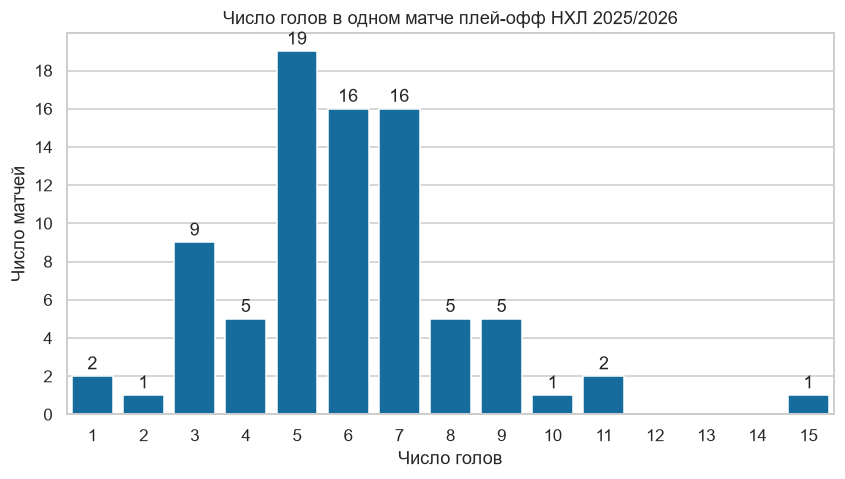

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
# countplot считает, сколько игр с каждым значением; order задаёт все значения от мин. до макс.,
# чтобы значения без игр (12, 13, 14 голов) тоже были видны на оси как «пустые» столбцы
sns.countplot(data=games, x='Total Score',
              order=list(range(games['Total Score'].min(), games['Total Score'].max() + 1)),
              color='#0072B2', ax=ax)
ax.bar_label(ax.containers[0], padding=2)                   # подписываем высоту каждого столбца числом
ax.yaxis.set_major_locator(MaxNLocator(integer=True))       # число матчей — целое
ax.set_xlabel('Число голов')
ax.set_ylabel('Число матчей')
ax.set_title('Число голов в одном матче плей-офф НХЛ 2025/2026')
plt.show()

Чтобы комментарии ниже опирались на проверяемые числа, посчитаем несколько характеристик распределения.

In [15]:
ts = games['Total Score']
n = len(ts)                                                      # число игр
margin = (games['Away Score'] - games['Home Score']).abs()      # разница в счёте (по модулю)
is_ot = games['Outcome'] != 'Final'                              # игры, дошедшие до овертайма

# Центр распределения: среднее, медиана и мода (самое частое значение)
print(f'Среднее: {ts.mean():.2f}, медиана: {ts.median():.0f}, мода: {ts.mode().tolist()} ({ts.value_counts().max()} игр)')
# Разброс и симметрия: сравнение дисперсии со средним помогает сопоставить с пуассоновским случаем
print(f'Дисперсия: {ts.var():.2f} (при среднем {ts.mean():.2f}), асимметрия: {ts.skew():.2f}')
print(f'Игр с 4–8 голами: {ts.between(4, 8).sum()} из {n} ({ts.between(4, 8).mean():.1%})')
print(f'Игр с числом голов ≤ 3: {(ts <= 3).sum()}, ≥ 10: {(ts >= 10).sum()}')
# Чётность суммы голов объясняет «пилообразный» вид гистограммы
print(f'Нечётная сумма голов: {(ts % 2 == 1).sum()} игр ({(ts % 2 == 1).mean():.1%}), чётная: {(ts % 2 == 0).sum()}')
print(f'Игр с овертаймом: {is_ot.sum()}; во всех разница ровно 1 гол: {(margin[is_ot] == 1).all()}; '
      f'во всех сумма нечётная: {(ts[is_ot] % 2 == 1).all()}')
print(f'Игр, выигранных с разницей в 1 гол: {(margin == 1).sum()} ({(margin == 1).mean():.1%})')

Среднее: 5.93, медиана: 6, мода: [5] (19 игр)
Дисперсия: 5.11 (при среднем 5.93), асимметрия: 0.78
Игр с 4–8 голами: 61 из 82 (74.4%)
Игр с числом голов ≤ 3: 12, ≥ 10: 4
Нечётная сумма голов: 54 игр (65.9%), чётная: 28
Игр с овертаймом: 22; во всех разница ровно 1 гол: True; во всех сумма нечётная: True
Игр, выигранных с разницей в 1 гол: 36 (43.9%)


**Комментарий к гистограмме.**

* **Центр и форма.** Распределение одновершинное и умеренно скошено вправо (асимметрия ≈ 0,78). В среднем в игре забивают около 5,9 шайбы, медиана равна 6. Самое частое значение — 5 голов (19 игр), чуть реже встречаются 6 и 7 (по 16 игр).
* **Основная масса.** 4–8 голов в игре — это 61 из 82 игр (около 74 %). Совсем «сухих» игр мало: игр с тремя и менее голами 12, и лишь в трёх из них было один или два гола.
* **Правый хвост.** Редкие очень результативные игры: 10 и более голов было в 4 играх, а максимум — 15 голов — выделяется как выброс (подробнее — в задании 6).
* **Левая граница.** Меньше одного гола в игре не бывает: в плей-офф ничьих нет, а овертайм играют до первой шайбы, поэтому 0 : 0 невозможно. Распределение «упирается» в единицу слева, отсюда и скос вправо.
* **Разброс.** Дисперсия (5,1) немного меньше среднего (5,9). У пуассоновской величины дисперсия равна среднему, то есть число голов в игре изменяется чуть более «кучно», чем при чисто случайном потоке голов.
* **«Пилообразный» рисунок.** Нечётные значения заметно чаще соседних чётных (4 против 5, 8 против 7 и т. д.): нечётная сумма голов в 54 играх из 82 (около 66 %). Это объясняется тем, что чётность суммы голов совпадает с чётностью разницы в счёте. Все 22 игры с овертаймом заканчиваются с разницей ровно в 1 гол (сумма всегда нечётная), и ещё в 14 играх из 60, сыгранных в основное время, разница тоже составила один гол (всего таких игр 36 из 82, то есть около 44 %).

## Задание 6. Самые нерезультативные и самые результативные игры

Выбираем игры, в которых суммарное число голов равно минимальному (максимальному) значению.

In [16]:
tot = games['Total Score']
# Булева маска tot == tot.min() выбирает все игры с минимальным числом голов (их может быть несколько)
[gameInfo(g) for g in games.index[tot == tot.min()]]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [17]:
# То же для максимума — самые результативные игры
[gameInfo(g) for g in games.index[tot == tot.max()]]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Две самые «сухие» игры закончились со счётом 1 : 0, причём обе в овертайме (единственный гол был забит в дополнительное время). Самая результативная игра — одна: 15 голов.

## Задание 7. Число игроков, участвовавших в игре

Для каждой игры нужно сосчитать число **различных** игроков обеих команд, побывавших на льду. Берём 14 столбцов: по шесть полевых позиций и вратарь для каждой команды (`... Player on the Ice #1–#6` и `... Goalie`). 

Переводим столбцы в «длинный» формат (`melt`), отбрасываем пропуски и считаем `nunique` по играм. Один игрок встречается в тысячах событий, но считается один раз. Вратари всегда присутствуют и среди полевых позиций, и в отдельном столбце, поэтому повторно они не считаются.

In [ ]:
# 14 столбцов с игроками на льду: по шесть полевых позиций и вратарь у каждой команды
player_cols = [c for c in events.columns if 'Player on the Ice' in c or 'Goalie' in c]
assert len(player_cols) == 14, player_cols

# melt: из «широкой» таблицы (14 столбцов) делаем «длинную» (одна строка = один игрок в одном событии)
players_long = (events[['Game ID'] + player_cols]
                .melt(id_vars='Game ID', value_name='Player')
                .dropna(subset=['Player']))                         # выбрасываем пропуски (нет игрока на позиции)
# nunique — число различных игроков в каждой игре
player_count = players_long.groupby('Game ID')['Player'].nunique()

players = pd.DataFrame({
    'Game Info': [gameInfo(g) for g in player_count.index],         # описание игры
    'Player Count': player_count.values,                            # число игроков
}, index=player_count.index)

# Выводим игру (игры) с максимальным числом участников
players[players['Player Count'] == players['Player Count'].max()]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Для контекста — пять игр с наибольшим числом участников (при равных значениях игры идут в порядке возрастания `Game ID`) и общая статистика.

In [19]:
# Пять игр с наибольшим числом игроков; kind='stable' сохраняет порядок Game ID при равных значениях
display(players.sort_values('Player Count', ascending=False, kind='stable').head(5))
players['Player Count'].describe().round(2)     # общая статистика числа игроков в игре

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40
2025030112,"Buffalo Sabres - Boston Bruins (2 - 4, Final, ...",39
2025030114,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ...",39
2025030185,"Edmonton Oilers - Anaheim Ducks (4 - 1, Final,...",39
2025030215,"Buffalo Sabres - Montréal Canadiens (3 - 6, Fi...",39


count    82.00
mean     38.12
std       0.36
min      38.00
25%      38.00
50%      38.00
75%      38.00
max      40.00
Name: Player Count, dtype: float64

**Замечание о расхождении с примером из условия.** В примере для игры `2025030216` указано 41 игрока, а у меня 40. Если считать число уникальных значений **вместе с `NaN`**, пропуск засчитывается как ещё один «игрок». 

## Задание 8. Расстояние до ворот для бросков

Рассматриваем события `shot-on-goal`, `goal` (точные броски) и `missed-shot` (неточные); всего их 7266.

**Какие ворота атакуются.** Ворота хозяев расположены слева, если `Home Team's Defending Side == 'left'`; тогда хозяева атакуют правые ворота (`X = 89`), а гости — левые (`X = −89`). При `right` — наоборот. Важно: сторона **меняется по ходу игры** (команды меняются воротами между периодами), поэтому её нужно брать из той же строки, что и бросок, а не одну на всю игру.

В векторной записи: смещение по `y` до створа равно `y + 3` при `y < −3`, `y − 3` при `y > 3` и нулю в створе, а расстояние — `hypot(x − X, смещение)`.

In [62]:
X_COL = 'X Coordinate on the Ice Rink'
Y_COL = 'Y Coordinate on the Ice Rink'

# Типы событий, которые считаем бросками (точные: shot-on-goal, goal; неточные: missed-shot)
shot_types = ['shot-on-goal', 'goal', 'missed-shot']
shot_mask = events['Play Type'].isin(shot_types)            # True для строк-бросков

# Кто бросает: хозяева или гости (сравниваем бросавшую команду с хозяевами матча)
is_home_shot = events['Team Making the Play'] == events['Home Team']
home_defends_left = events["Home Team's Defending Side"] == 'left'   

# Атакует ли бросающая команда правые ворота (X = 89)
#   хозяева: атакуют правые, если защищают левые;  гости: наоборот
attacks_right = pd.Series(np.where(is_home_shot, home_defends_left, ~home_defends_left), index=events.index)
goal_x = pd.Series(np.where(attacks_right, 89, -89), index=events.index)   # X-координата атакуемых ворот


def distance_to_goal(x, y, goal_x):
    """Расстояние (в футах) от точки (x, y) до ближайшей точки створа ворот с координатой X = goal_x."""
    # Смещение по y до створа (створ — отрезок от y = -3 до y = 3): внутри створа смещения нет
    dy = np.where(y < -3, y + 3, np.where(y > 3, y - 3, 0.0))
    return np.hypot(x - goal_x, dy)        


# Считаем расстояние только для бросков, для остальных событий оставляем NaN
events['Shot Length'] = np.where(shot_mask, distance_to_goal(events[X_COL], events[Y_COL], goal_x), np.nan)

# Проверим: ровно 7266 бросков, у всех бросков расстояние посчитано, у остальных событий — NaN
assert shot_mask.sum() == 7266
assert events.loc[shot_mask, 'Shot Length'].notna().all()
assert events.loc[~shot_mask, 'Shot Length'].isna().all()

In [63]:

events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])][['Game ID', 'Play Type', 'Shot Length']].round(3)

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


**Проверка.** Проверим логику выбора ворот: если она верна, почти все броски должно выполняться с «атакующей» половины площадки (то есть с той же стороны от центра, где находятся атакуемые ворота).

In [64]:

# Дополнительная проверка выбора ворот: бросок должен выполняться с той же стороны, где атакуемые ворота
side = np.where(attacks_right, 1, -1)                       # +1: цель справа, −1: цель слева
from_own_half = (events[X_COL] * side < 0) & shot_mask       # бросок с «чужой» для цели половины
print(f'Доля бросков с атакующей половины: {1 - from_own_half[shot_mask].mean():.1%}')

Доля бросков с атакующей половины: 97.1%


## Задание 9. Длина точных и неточных бросков

Группы: **точные** броски — `shot-on-goal` и `goal` (4623 броска), **неточные** — `missed-shot` (2643 броска). Группы разного размера, поэтому гистограммы  нормируем *внутри каждой группы*: `stat='density'` вместе с `common_norm=False`. Без `common_norm=False` плотности делились бы на общее число бросков, и более многочисленная группа визуально «перевешивала» бы другую.


{'on goal': 4623, 'missed': 2643}


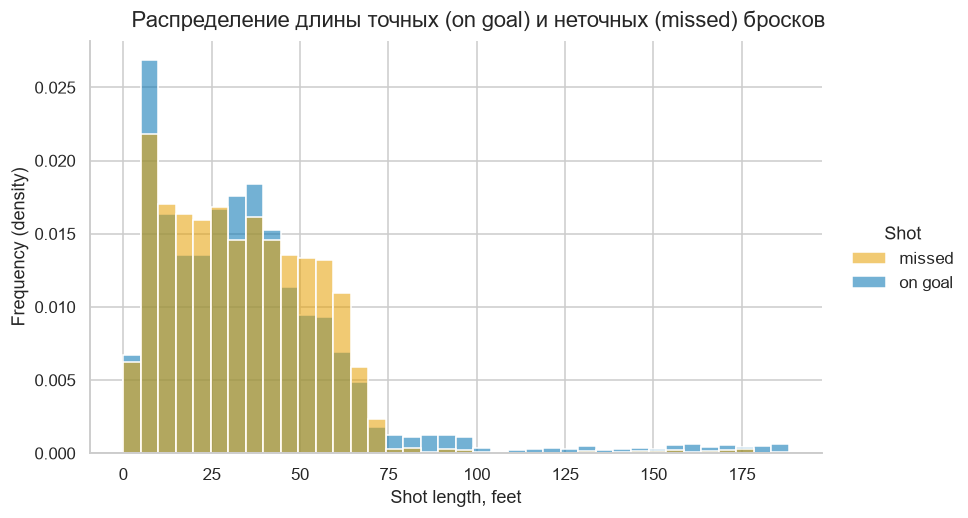

In [ ]:
shots = events.loc[shot_mask].copy()      
# Группа броска: «missed» — неточный, «on goal» — точный (бросок в створ или гол)
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')
print(shots['Shot'].value_counts().to_dict())

palette = {'missed': '#E69F00', 'on goal': '#0072B2'}      
# stat='density' + common_norm=False — нормируем гистограмму ВНУТРИ каждой группы,
g = sns.displot(data=shots, x='Shot Length', hue='Shot', hue_order=['missed', 'on goal'],
                stat='density', common_norm=False, binwidth=5, palette=palette,
                alpha=0.55, height=4.6, aspect=1.7)
g.set_axis_labels('Shot length, feet', 'Frequency (density)')
plt.suptitle('Распределение длины точных (on goal) и неточных (missed) бросков', y=1.02)
plt.show()

Чтобы выводы опирались на числа, посчитаем характеристики групп.

In [25]:
# Описательные статистики длины броска в каждой группе
print(shots.groupby('Shot')['Shot Length'].describe().round(2).to_string())
print()
# Доли «дальних» бросков и квантили — для количественного описания хвоста распределения
for name, s in shots.groupby('Shot')['Shot Length']:
    print(f'{name:8s} дальше 70 футов: {(s > 70).mean():5.1%} | дальше 100 футов: {(s > 100).mean():5.1%} | '
          f'95%-квантиль: {s.quantile(.95):5.1f} | 99%-квантиль: {s.quantile(.99):5.1f}')
within100 = shots[shots['Shot Length'] <= 100]       # без хвоста: броски с расстояния не больше 100 футов
print('\nТолько броски до 100 футов — среднее и медиана:')
print(within100.groupby('Shot')['Shot Length'].agg(['mean', 'median']).round(2).to_string())

# Распределение бросков каждой группы по интервалам расстояния (в процентах от группы)
bins10 = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 200]
shares = pd.crosstab(pd.cut(shots['Shot Length'], bins10, right=False), shots['Shot'], normalize='columns') * 100
print('\nДоля бросков группы (%) по интервалам расстояния, футы:')
print(shares.round(1).to_string())

          count   mean    std  min    25%    50%    75%     max
Shot                                                           
missed   2643.0  34.01  22.31  0.0  16.16  32.25  49.04  185.07
on goal  4623.0  36.21  30.00  0.0  15.00  31.83  47.01  188.22

missed   дальше 70 футов:  2.4% | дальше 100 футов:  0.9% | 95%-квантиль:  65.0 | 99%-квантиль:  91.7
on goal  дальше 70 футов:  7.2% | дальше 100 футов:  3.5% | 95%-квантиль:  86.7 | 99%-квантиль: 169.3

Только броски до 100 футов — среднее и медиана:
          mean  median
Shot                  
missed   32.95   32.00
on goal  32.07   30.68

Доля бросков группы (%) по интервалам расстояния, футы:
Shot         missed  on goal
Shot Length                 
[0, 10)        13.9     16.6
[10, 20)       16.6     15.1
[20, 30)       16.3     15.2
[30, 40)       15.5     18.1
[40, 50)       13.9     13.2
[50, 60)       13.1      9.0
[60, 70)        8.2      5.7
[70, 80)        1.0      1.4
[80, 90)        0.3      1.3
[90, 100)       0.2   

Как меняется вероятность гола с расстоянием (среди точных бросков):

In [26]:
# Среди точных бросков: доля голов (остальные — броски, отбитые вратарём) по интервалам расстояния
on_goal = shots[shots['Shot'] == 'on goal']
by_dist = on_goal.assign(Goal=on_goal['Play Type'] == 'goal',                      # True, если бросок закончился голом
                         Bin=pd.cut(on_goal['Shot Length'], [0, 20, 40, 60, 100, 200], right=False))
(by_dist.groupby('Bin', observed=True)['Goal'].agg(['size', 'mean'])               # число бросков и доля голов
        .rename(columns={'size': 'Точных бросков', 'mean': 'Доля голов'}).round(3))

,Точных бросков,Доля голов
Bin,,
"[0, 20)",1465,0.169
"[20, 40)",1536,0.107
"[40, 60)",1025,0.044
"[60, 100)",437,0.027
"[100, 200)",160,0.106


### Вывод из гистограммы

1. **Основная масса бросков у обеих групп почти одинакова.** У обеих гистограмм острый пик на расстоянии 5–10 футов от ворот (у точных бросков он выше), затем идёт плато до  50 футов и резкий спад после  70 футов (синяя линия зоны нападения находится примерно в 64 футах от ворот, и почти все броски делаются из зоны нападения). До 60 футов приходится 87–90 % бросков обеих групп. Среднее и медиана для бросков до 100 футов практически совпадают (около 32–33 футов у неточных и около 31–32 у точных), то есть расстояние само по себе слабо отличает точный бросок от неточного. Отличие скромное: дальние броски (50–70 футов) чаще оказываются неточными (21 % неточных против 15 % точных бросков группы), а самые ближние (до 10 футов) — чаще точными (14 % против 17 %). Вероятность гола при этом резко падает с расстоянием: от  17 % при броске с расстояния до 20 футов до  3 % при 60–100 футах (таблица выше).
2. **У точных бросков есть длинный правый хвост до  190 футов, у неточных его почти нет.** Дальше 70 футов — около 7 % точных бросков против около 2 % неточных; дальше 100 футов — 3,5 % против 0,9 %; 99%-квантиль длины точного броска  169 футов, неточного —  92 фута. Хвост хорошо виден и в доле голов: после спада до 3 % при 60–100 футах она снова вырастает до  11 % для бросков дальше 100 футов.





**Итог.** Длинный хвост точных бросков со своей половины площадки — не ошибка данных, а следствие реальных игровых ситуаций: (1) голы в пустые ворота в концовке игры, когда проигрывающий снимает вратаря; (2) дальние броски из своей зоны, которые отбивает вратарь, особенно часто при игре в меньшинстве. Неточных дальних бросков в данных почти нет (из своей половины всего 27 против 185 точных), вероятно потому, что дальние промахи обычно не фиксируются как отдельные броски (выглядят как обычные «выбросы» шайбы).

Для наглядности — состав хвоста (броски дальше 70 футов) по типам событий:

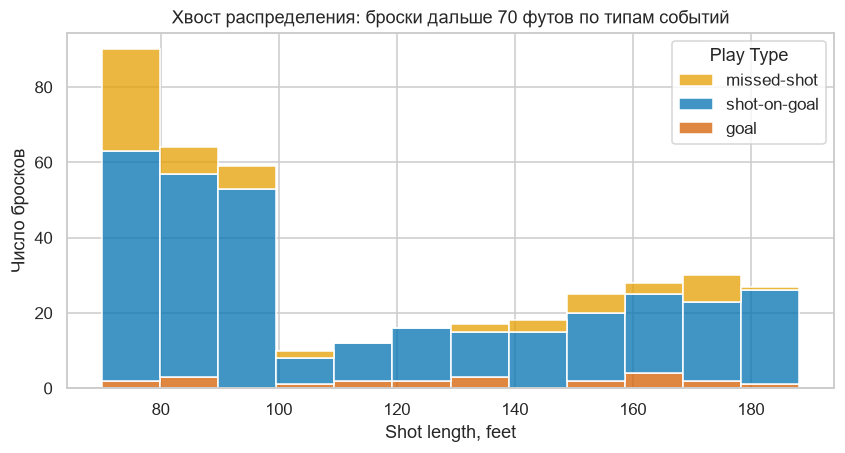

In [30]:
far = shots[shots['Shot Length'] > 70]          # только «хвост»: броски дальше 70 футов
fig, ax = plt.subplots(figsize=(9, 4.2))
# multiple='stack' — столбцы разных типов событий складываются друг на друга в каждом интервале
sns.histplot(data=far, x='Shot Length', hue='Play Type',
             hue_order=['missed-shot', 'shot-on-goal', 'goal'],
             multiple='stack', binwidth=10, palette={'missed-shot': '#E69F00',
                                                    'shot-on-goal': '#0072B2',
                                                    'goal': '#D55E00'}, ax=ax)
ax.set_xlabel('Shot length, feet')
ax.set_ylabel('Число бросков')
ax.set_title('Хвост распределения: броски дальше 70 футов по типам событий')
plt.show()

За пределами 100 футов (это уже своя половина площадки) преобладают броски, отбитые вратарём (`shot-on-goal`); голы (`goal`) составляют малую, но заметную часть, а неточных бросков (`missed-shot`) там мало. Интервал 70–100 футов — это броски из нейтральной зоны: неточные броски здесь встречаются заметно чаще, чем дальше 100 футов.

In [ ]:

# scipy нужен для статистических тестов (корреляция, t-критерий, биномиальный тест).
try:
    from scipy import stats
except ModuleNotFoundError:
    import sys, subprocess, importlib
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'scipy'])
    importlib.invalidate_caches()
    from scipy import stats

from rink import plot_rink      # функция рисования хоккейной площадки (из rink.py)

## Задание 10. Доля точных бросков среди незаблокированных

Незаблокированные броски — это `shot-on-goal`, `goal` и `missed-shot`. Точные — `shot-on-goal` и `goal`. Считаем долю для каждой пары «игра — команда» (164 = 82 игры × 2 команды).

 (1) Оставляем только незаблокированные броски; 
 (2) помечаем точные (`shot-on-goal`, `goal`) значением `True`; 
 (3) для каждой пары «игра — команда» берём среднее этого столбца — это и есть доля точных бросков; 
 (4) смотрим на распределение доли и сравниваем победителей с проигравшими.

In [ ]:
# Берём только незаблокированные броски: бросок в створ, гол и бросок мимо.
# Заблокированные (blocked-shot) в знаменатель не входят.
shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()

# Точный бросок = бросок в створ ИЛИ гол (гол — тоже бросок, попавший в створ).
shots['On Goal'] = shots['Play Type'].isin(['shot-on-goal', 'goal'])

# Группируем по паре (игра, бросавшая команда). Для blocked-shot поле Team Making the Play — бросавшая команда,
numshots = shots.groupby(['Game ID', 'Team Making the Play']).agg(
    **{'Unblocked Shots': ('On Goal', 'size'),            # сколько всего незаблокированных бросков
       'Shots on Goal': ('On Goal', 'sum'),               # точных бросков
       'Share of Shots on Goal': ('On Goal', 'mean')})    # доля точных 
print(numshots['Share of Shots on Goal'])    

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
                                      ...   
2025030414  Vegas Golden Knights    0.583333
2025030415  Carolina Hurricanes     0.558140
            Vegas Golden Knights    0.510204
2025030416  Carolina Hurricanes     0.638889
            Vegas Golden Knights    0.594595
Name: Share of Shots on Goal, Length: 164, dtype: float64


Распределение показателя и сравнение победителей с проигравшими:

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64
Общая доля: 0.636; среднее число незаблокированных бросков за игру у команды: 44.3
Std при чистой случайности ~ 0.072, наблюдаемый std = 0.085
           count   mean    std
Result                        
победа        82  0.632  0.087
поражение     82  0.646  0.083
TtestResult(statistic=np.float64(-1.0147265649019368), pvalue=np.float64(0.3117520075889634), df=np.float64(161.71035114727076))


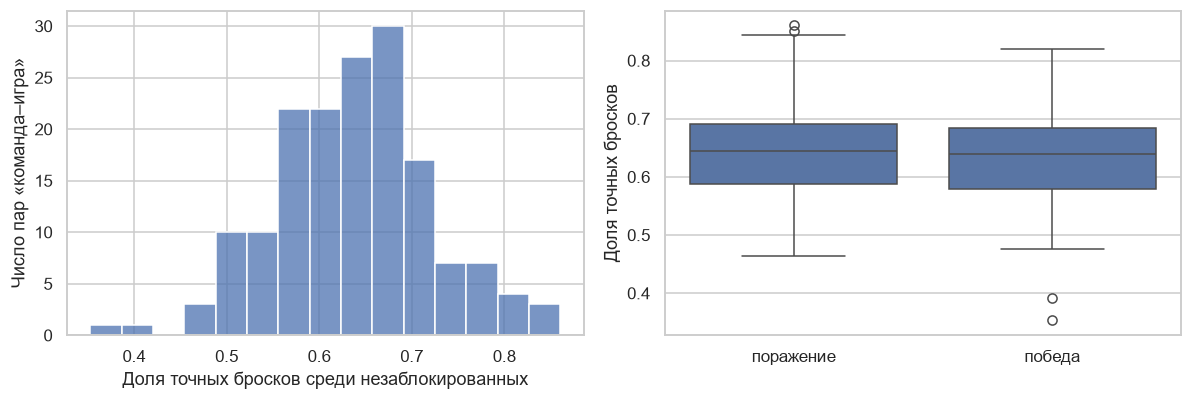

In [ ]:
# Описательные статистики доли точных бросков по всем 164 парам «игра — команда»
print(numshots['Share of Shots on Goal'].describe().round(3))

# Сравнение с «чистой случайностью»: если бы каждый бросок независимо попадал в створ с одной и той же
# вероятностью p, то доля в игре из n бросков имела бы стандартное отклонение sqrt(p*(1-p)/n).
p_all = numshots['Shots on Goal'].sum() / numshots['Unblocked Shots'].sum()   # общая доля точных бросков
mean_n = numshots['Unblocked Shots'].mean()                                    # типичное число бросков за игру
print(f'Общая доля: {p_all:.3f}; среднее число незаблокированных бросков за игру у команды: {mean_n:.1f}')
print(f'Std при чистой случайности ~ {np.sqrt(p_all * (1 - p_all) / mean_n):.3f}, наблюдаемый std = {numshots["Share of Shots on Goal"].std():.3f}')

# Присоединяем счёт игры, чтобы понять, выиграла ли команда в этой игре
res = numshots.reset_index().merge(games[['Away Team', 'Home Team', 'Away Score', 'Home Score']],
                                   left_on='Game ID', right_index=True)
is_home = res['Team Making the Play'] == res['Home Team']               
res['Team Score'] = np.where(is_home, res['Home Score'], res['Away Score'])   # голы самой команды
res['Opp Score'] = np.where(is_home, res['Away Score'], res['Home Score'])    # голы соперника
res['Result'] = np.where(res['Team Score'] > res['Opp Score'], 'победа', 'поражение')   # ничьих нет
print(res.groupby('Result')['Share of Shots on Goal'].agg(['count', 'mean', 'std']).round(3))

# t-критерий Уэлча (equal_var=False): отличаются ли средние доли у победителей и проигравших?
# Если p-value велико (> 0.05), различие можно считать случайным.
print(stats.ttest_ind(res.loc[res['Result'] == 'победа', 'Share of Shots on Goal'],
                      res.loc[res['Result'] == 'поражение', 'Share of Shots on Goal'], equal_var=False))

# Две картинки: гистограмма доли и «ящики с усами» по группам победа/поражение
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(numshots['Share of Shots on Goal'], bins=15, ax=ax[0])
ax[0].set_xlabel('Доля точных бросков среди незаблокированных')
ax[0].set_ylabel('Число пар «команда–игра»')
sns.boxplot(data=res, x='Result', y='Share of Shots on Goal', ax=ax[1])
ax[1].set_xlabel('')
ax[1].set_ylabel('Доля точных бросков')
plt.tight_layout()

**Вывод.**
- Типичная доля точных бросков — около **64 %** (среднее и медиана 0.639, по всем броскам 0.636), в отдельных играх она колеблется примерно от 0.35 до 0.86. Распределение близко к колоколообразному и симметричное.
- Разброс по играм (0.085) лишь немного больше, чем получился бы при чисто случайном исходе каждого броска при одной и той же вероятности (≈ 0.072 при ~44 бросках за игру). Значит, значительная часть вариации между играми — это обычный случайный шум, а не устойчивое «качество» команды в конкретном матче.
- Доля точных бросков **не отличает победителей от проигравших**: 0.632 у победителей против 0.646 у проигравших, различие статистически незначимо ( p = 0.31). То есть исход матча определяется не тем, какая часть незаблокированных бросков попала в створ, а другими факторами: числом бросков, их качеством (расстояние, место), игрой вратарей, реализацией большинства и т. д.

## Задание 11. Команды с самыми высокими и самыми низкими средними долями точных бросков

Усредняем доли из задания 10 по играм каждой команды и берём `nlargest(5)` / `nsmallest(5)`. Так как у команд разное число игр, дополнительно смотрим на стандартную ошибку среднего.

In [34]:
# Средняя (по играм) доля точных бросков каждой команды: сначала усредняем по играм внутри команды
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()
print(avgnumshots.nlargest(5).round(3))    # пять самых высоких значений
print()
print(avgnumshots.nsmallest(5).round(3))   # пять самых низких значений

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64


Чтобы корректно интерпретировать результат, посмотрим на число сыгранных игр и стандартную ошибку среднего (`se`):

In [35]:
# Для контекста: у команд разное число игр (от 4 до 22), поэтому средние оценены с разной точностью.
# se (стандартная ошибка среднего) = std / sqrt(число игр): чем она меньше, тем надёжнее среднее.
summary = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].agg(['mean', 'std', 'count'])
summary['se'] = summary['std'] / np.sqrt(summary['count'])
summary.sort_values('mean', ascending=False).round(3)

,mean,std,count,se
Team Making the Play,,,,
Edmonton Oilers,0.706,0.115,6,0.047
Philadelphia Flyers,0.684,0.124,10,0.039
Dallas Stars,0.670,0.087,6,0.035
Minnesota Wild,0.656,0.078,11,0.023
Colorado Avalanche,0.653,0.065,13,0.018
Anaheim Ducks,0.649,0.055,12,0.016
Montréal Canadiens,0.644,0.103,19,0.024
Los Angeles Kings,0.642,0.045,4,0.022
Boston Bruins,0.638,0.035,6,0.014


**Комментарий.**
- Лидеры: Edmonton Oilers (0.706), Philadelphia Flyers (0.684), Dallas Stars (0.670), Minnesota Wild (0.656), Colorado Avalanche (0.653). Аутсайдеры: Pittsburgh Penguins (0.554), Utah Mammoth (0.599), Carolina Hurricanes (0.615), Tampa Bay Lightning и Buffalo Sabres (по 0.626).
- Различия между командами в целом невелики: почти все значения лежат в диапазоне 0.60–0.70, общее среднее ≈ 0.64.
- Надёжность оценок разная. Команды, вылетевшие рано, сыграли 4–7 игр, поэтому их средние шумные (у Edmonton se ≈ 0.047, у Utah ≈ 0.060, у Tampa Bay ≈ 0.048). Лидерство Edmonton, Philadelphia и Dallas отстоит от среднего меньше, чем на полторы–две стандартные ошибки, так что убедительно утверждать, что они «точнее» остальных, нельзя.
- Самый «надёжный» результат — у **Pittsburgh Penguins**: 0.554 при se ≈ 0.019, это примерно на 4 стандартные ошибки ниже общего среднего. Это единственная команда, у которой низкая доля точных бросков выглядит устойчивой особенностью, а не случайностью. Обратите внимание, что Carolina Hurricanes (19 игр, se ≈ 0.014) — тоже ниже среднего, хотя это одна из самых успешных команд плей-офф: значит, высокая точность бросков не является необходимым условием успеха.

## Задание 12. Среднее число бросков в створ и голов за игру

Число бросков в створ = `shot-on-goal` + `goal` (гол — тоже бросок в створ), делим на число игр, которые сыграла команда (команда могла играть и дома, и в гостях).

Суммируем броски в створ и голы по командам и делим на число игр, сыгранных командой.

In [36]:
# Сколько игр сыграла каждая команда: считаем её появления и среди гостей, и среди хозяев
n_games = pd.concat([games['Away Team'], games['Home Team']]).value_counts()

# Броски в створ = shot-on-goal + goal, суммарно за плей-офф для каждой команды
on_goal = events[events['Play Type'].isin(['shot-on-goal', 'goal'])].groupby('Team Making the Play').size()
# Голы — события goal; Team Making the Play для гола — забившая команда
goals_by_team = events[events['Play Type'] == 'goal'].groupby('Team Making the Play').size()

# Делим суммы на число игр команды, получаем «в среднем за игру»
avgshots = pd.DataFrame({'Shot': on_goal / n_games, 'Goal': goals_by_team / n_games})
avgshots.index.name = 'Team Making the Play'
avgshots.round(3)

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## Задание 13. Связь между числом бросков в створ и голами

**Идея решения.** Строим диаграмму `seaborn.regplot` по таблице из задания 12 и дополнительно измеряем связь числами (корреляция Пирсона и Спирмена, наклон прямой).

Pearson r = 0.521 (p = 0.039), R^2 = 0.271
Spearman rho = 0.578 (p = 0.019)
Наклон прямой = 0.156 гола на дополнительный бросок, стандартная ошибка 0.069


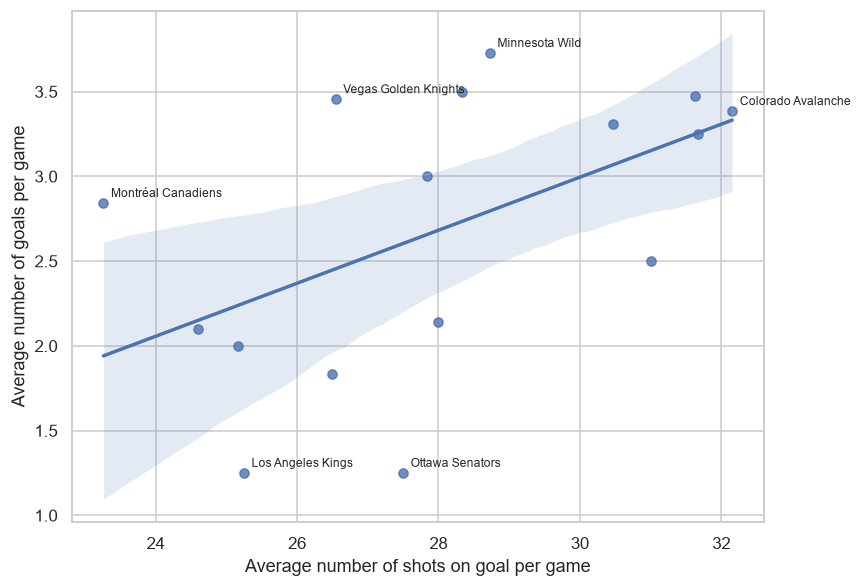

In [ ]:
# Количественно измеряем связь двух показателей (16 точек — по одной на команду)
r, p = stats.pearsonr(avgshots['Shot'], avgshots['Goal'])         # линейная корреляция и её p-value
rho, p_s = stats.spearmanr(avgshots['Shot'], avgshots['Goal'])    
lr = stats.linregress(avgshots['Shot'], avgshots['Goal'])         # прямая регрессии: наклон, свободный член, ошибка
print(f'Pearson r = {r:.3f} (p = {p:.3f}), R^2 = {r**2:.3f}')
print(f'Spearman rho = {rho:.3f} (p = {p_s:.3f})')
print(f'Наклон прямой = {lr.slope:.3f} гола на дополнительный бросок, стандартная ошибка {lr.stderr:.3f}')

# Регрессионная диаграмма: точки — команды, линия — МНК-прямая, полоса — 95% доверительный интервал
plt.figure(figsize=(8, 5.5))
ax = sns.regplot(data=avgshots, x='Shot', y='Goal')
# Подписываем только 5 команд с наибольшим отклонением от прямой + команды с минимумом и максимумом бросков
resid = avgshots['Goal'] - (lr.intercept + lr.slope * avgshots['Shot'])
to_label = set(resid.abs().nlargest(5).index) | {avgshots['Shot'].idxmin(), avgshots['Shot'].idxmax()}
for team in to_label:
    ax.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']),
                xytext=(5, 4), textcoords='offset points', fontsize=8)
ax.set_xlabel('Average number of shots on goal per game')
ax.set_ylabel('Average number of goals per game')
plt.tight_layout()

**Комментарий.** Связь **есть, положительная, но умеренная**.
- Коэффициент корреляции Пирсона r ≈ 0.52 (p ≈ 0.04), Спирмена ρ ≈ 0.58 (p ≈ 0.02): при 16 наблюдениях это статистически значимо на уровне 5 %. Наклон прямой ≈ 0.16, т. е. в среднем один дополнительный бросок в створ за игру соответствует примерно +0.16 гола за игру (примерно 10 % реализации; для сравнения, по всем командам голов на бросок в створ ≈ 0.096).
- Но объясняется лишь около 27 % разброса (R² ≈ 0.27), доверительная полоса вокруг прямой широкая, а наклон оценён неточно (стандартная ошибка ≈ 0.07). При всего 16 командах и 4–22 играх на команду вывод нельзя считать жёстким.
- Заметные отклонения от прямой (подписаны на графике): Vegas Golden Knights, Minnesota Wild и Montréal Canadiens забивают заметно больше, чем «положено» по числу бросков (высокая реализация), а Ottawa Senators и Los Angeles Kings — заметно меньше (по 1.25 гола за игру при 25–28 бросках). Это команды, сыгравшие мало игр (Ottawa, LA — по 4), поэтому отчасти это случайность; но для Vegas (22 игры) и Montréal (19 игр) отклонения основаны на большой выборке.
- Итог: количество бросков в створ — полезный, но далеко не единственный фактор результативности; важны качество моментов, игра вратарей, реализация большинства.

## Задание 14. Матч с наибольшим числом ударов по воротам

Считаем все четыре типа ударов: `shot-on-goal`, `goal`, `missed-shot`, `blocked-shot`.

Считаем число ударов (4 типа событий) по каждой игре и берём игру с максимумом через `idxmax`.

In [38]:
# Все четыре типа ударов по воротам (включая промахи и заблокированные)
all_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]
shots_per_game = all_shots.groupby('Game ID').size()    # число ударов в каждой игре
idxmax = shots_per_game.idxmax()                         # Game ID игры с максимумом
print('Ударов в матче:', shots_per_game.max(), '| Game ID:', idxmax)
print(gameInfo(idxmax))                                  # описание игры нашей функцией из задания 3
shots_per_game.nlargest(5)                               # для сравнения — пять самых «ударных» игр

Ударов в матче: 208 | Game ID: 2025030132
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


Game ID
2025030132    208
2025030164    169
2025030413    163
2025030126    156
2025030175    154
dtype: int64

## Задание 15. Диаграмма рассеивания бросков в найденном матче

Приводим координаты так, чтобы гости бросали в левые ворота, а хозяева — в правые. Для этого использую поле `Home Team's Defending Side`: если хозяева защищают правые ворота, меняем знак обеих координат. В этом матче хозяева защищают правые ворота в **нечётных периодах** — ровно то, что требуется в условии (`(x, y) → (−x, −y)` в нечётных периодах); соответствие проверяется `assert`-ом в ячейке. Подход через `Defending Side` универсален и работает для любой игры.

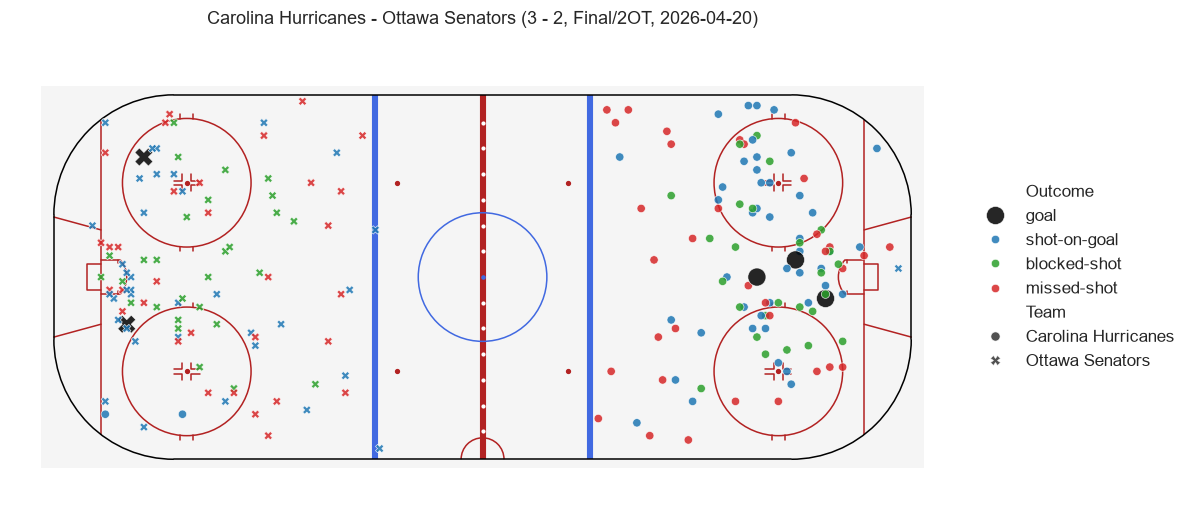

In [ ]:
# Берём удары только из найденной игры
game_shots = all_shots[all_shots['Game ID'] == idxmax].copy()

# Приводим координаты к единому виду: гости бьют в левые ворота, хозяева — в правые.
# В исходных данных стороны меняются каждый период. Если хозяева защищают правые ворота,
# то все координаты «зеркалим» поворотом на 180°: (x, y) -> (-x, -y).
flip = game_shots["Home Team's Defending Side"] == 'right'
assert (flip == (game_shots['Period'] % 2 == 1)).all()      # проверка: «правая сторона» совпадает с «нечётным периодом»
game_shots['x'] = np.where(flip, -game_shots['X Coordinate on the Ice Rink'], game_shots['X Coordinate on the Ice Rink'])
game_shots['y'] = np.where(flip, -game_shots['Y Coordinate on the Ice Rink'], game_shots['Y Coordinate on the Ice Rink'])

game_shots = game_shots.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

plt.figure(figsize=(11, 5))
plot_rink()                       # сначала рисуем площадку (линии, круги вбрасывания, ворота)
# Поверх — точки: цвет = исход удара, форма маркера = команда; голы сделаны крупнее и чёрными
sns.scatterplot(data=game_shots, x='x', y='y', hue='Outcome', style='Team',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette={'goal': 'black', 'shot-on-goal': '#1f77b4', 'blocked-shot': '#2ca02c', 'missed-shot': '#d62728'},
                size='Outcome', sizes={'goal': 140, 'shot-on-goal': 30, 'blocked-shot': 30, 'missed-shot': 30},
                legend='brief', alpha=0.85, zorder=3)
plt.axis('equal')                 
plt.axis('off')                   
plt.title(gameInfo(idxmax))
plt.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)   
plt.tight_layout()

Проверка корректности преобразования (удары хозяев — справа, гостей — слева) и число ударов каждого типа:

In [40]:
# Проверка преобразования: после него удары хозяев должны быть справа (x > 0), гостей — слева (x < 0).
game_shots['Is Home'] = game_shots['Team'] == game_shots['Home Team']
game_shots.groupby('Is Home')['x'].agg(['count', 'median'])

,count,median
Is Home,,
False,99,-70.0
True,109,65.0


In [41]:
# Сколько ударов каждого типа сделала каждая команда
pd.crosstab(game_shots['Team'], game_shots['Outcome'])[['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot']]

Outcome,goal,shot-on-goal,blocked-shot,missed-shot
Team,,,,
Carolina Hurricanes,3,46,26,34
Ottawa Senators,2,37,28,32


Матч Carolina Hurricanes — Ottawa Senators (3 : 2, 2 овертайма) — самый затяжной: 208 ударов. Хозяева (Carolina) атакуют правые ворота, гости (Ottawa) — левые; удары сосредоточены в зонах нападения обеих команд. Из 208 ударов бросков в створ 83 (46 и 37 без голов), заблокировано 54 (26 и 28), мимо ушло 66 (34 и 32), а голами стали только 5 (3 и 2) — по 3 и 2 гола у Carolina и Ottawa соответственно, что совпадает со счётом 3 : 2.

## Задание 16. Десять лучших бомбардиров плей-офф

Считаем события `goal` по полю `Player in the Event #1`. Если на границе топ-10 есть ничья, порядок внутри ничьей — по алфавиту, а не вошедшие игроки печатаются отдельной строкой.

Нужна одна вспомогательная функция `top10`, которая сортирует игроков по показателю, аккуратно обрабатывает ничьи на границе топ-10 и нумерует места.

In [42]:
def top10(s, name, tiebreak=None):
    """Десять лучших игроков из Series (индекс — имя игрока, значение — показатель).
    При равенстве значений порядок: сначала по tiebreak (если задан), затем по алфавиту.
    Если на границе топ-10 есть ничья, печатаем, кто ещё имеет такое же значение."""
    d = s.rename(name).to_frame()
    d.index.name = 'Player'
    d['tb'] = tiebreak.reindex(d.index).fillna(0) if tiebreak is not None else 0   # вспомогательный столбец для ничьих
    d = d.reset_index().sort_values([name, 'tb', 'Player'], ascending=[False, False, True]).reset_index(drop=True)
    edge = d.loc[9, name]                      # значение у игрока на 10-м месте
    tied = d[d[name] == edge]
    if len(tied) > 1 and (tied.index > 9).any():           # есть ли равные ему за пределами таблицы
        extra = d.loc[(d[name] == edge) & (d.index > 9), 'Player'].tolist()
        print(f'Ничья на границе ({name} = {edge}): в таблицу не поместились ещё {len(extra)}: ' + ', '.join(extra))
    out = d.head(10).drop(columns='tb')
    out.index = range(1, 11)                    # нумерация мест 1..10
    return out

goal_events = events[events['Play Type'] == 'goal']                       # все голы плей-офф
goals_scored = goal_events['Player in the Event #1'].value_counts()       # Player #1 в событии goal — автор гола
top10(goals_scored, 'Goals')

Ничья на границе (Goals = 7): в таблицу не поместились ещё 2: Nathan MacKinnon, Taylor Hall


,Player,Goals
1,Brett Howden,14
2,Pavel Dorofeyev,12
3,Logan Stankoven,11
4,Mitch Marner,10
5,Jordan Staal,8
6,Nikolaj Ehlers,8
7,Alex Newhook,7
8,Jackson Blake,7
9,Mark Stone,7
10,Matt Boldy,7


## Задание 17. Десять лучших по голевым передачам

Передачи — поля `Player in the Event #2` и `#3` в событиях `goal`.

In [43]:
# Голевые передачи: Player #2 и Player #3 в событии goal (у части голов ассистента нет — там NaN)
# Склеиваем два столбца в один, выбрасываем пропуски и считаем, сколько раз встретился каждый игрок.
assists = pd.concat([goal_events['Player in the Event #2'], goal_events['Player in the Event #3']]).dropna().value_counts()
top10(assists, 'Assists')

,Player,Assists
1,Jack Eichel,20
2,Mitch Marner,19
3,Jackson Blake,13
4,Lane Hutson,13
5,Martin Necas,12
6,Nick Suzuki,12
7,Shea Theodore,12
8,Taylor Hall,12
9,Kirill Kaprizov,11
10,Quinn Hughes,11


## Задание 18. Десять лучших по системе «гол + пас»

Очки = голы + голевые передачи. При равенстве очков выше стоит тот, у кого больше голов (как в официальной статистике НХЛ), затем — по алфавиту.

In [44]:
# Очки = голы + передачи. add(..., fill_value=0) корректно складывает, если игрок есть только в одной из таблиц
# (например, забивал, но не отдавал передач).
points = goals_scored.add(assists, fill_value=0).astype(int)
tbl = pd.DataFrame({'Goals': goals_scored, 'Assists': assists, 'Points': points}).fillna(0).astype(int)
# Как в официальной статистике НХЛ, при равных очках выше тот, у кого больше голов
top = top10(points, 'Points', tiebreak=goals_scored)
# Добавляем к таблице отдельные столбцы голов и передач, чтобы было видно состав очков
top.merge(tbl[['Goals', 'Assists']], left_on='Player', right_index=True).set_index(top.index)

Ничья на границе (Points = 16): в таблицу не поместились ещё 1: Lane Hutson


,Player,Points,Goals,Assists
1,Mitch Marner,29,10,19
2,Jack Eichel,22,2,20
3,Jackson Blake,20,7,13
4,Taylor Hall,19,7,12
5,Brett Howden,18,14,4
6,Nikolaj Ehlers,18,8,10
7,Shea Theodore,18,6,12
8,Pavel Dorofeyev,16,12,4
9,Logan Stankoven,16,11,5
10,Nick Suzuki,16,4,12


## Задание 19. Игроки с наибольшим средним числом бросков в створ за игру

Бросок в створ = `shot-on-goal` или `goal` (как в заданиях 8–12), игрок — `Player in the Event #1`. Среднее считаем **на одну игру, в которой игрок участвовал** (то есть появлялся на льду хотя бы в одном событии: столбцы `Player on the Ice #1–#6` обеих команд, вратари входят в эти столбцы).

In [ ]:
# 1) Сколько игр сыграл каждый игрок. Игрок «участвовал» в игре, если он хоть раз значится на льду.
#    Столбцы Player on the Ice #1–#6 обеих команд уже включают вратарей.
onice_cols = [c for c in events.columns if 'Player on the Ice' in c]
appear = (events[['Game ID'] + onice_cols].melt(id_vars='Game ID', value_name='Player')   
          .dropna(subset=['Player'])[['Game ID', 'Player']].drop_duplicates())            # убираем пропуски и повторы внутри игры
games_played = appear.groupby('Player').size().rename('Games')                           # число уникальных игр у игрока

def per_game(play_types, name):
    """Сколько раз игрок был автором события заданных типов (Player #1), всего и в среднем на игру."""
    cnt = events[events['Play Type'].isin(play_types)]['Player in the Event #1'].value_counts().rename('Total')
    d = pd.concat([cnt, games_played], axis=1, join='inner')     # оставляем игроков, для которых есть и события, и игры
    d[name] = d['Total'] / d['Games']                            # среднее на одну сыгранную игру
    return d

# 2) Броски в створ (shot-on-goal + goal) в среднем за игру
sog = per_game(['shot-on-goal', 'goal'], 'Shots on Goal per Game')
res19 = sog.sort_values(['Shots on Goal per Game', 'Total'], ascending=False).head(10)
res19.index.name = 'Player'
res19.round(3)

,Total,Games,Shots on Goal per Game
Player,,,
Jason Robertson,30,6,5.000
Dylan Guenther,27,6,4.500
Nikita Kucherov,31,7,4.429
Matt Boldy,48,11,4.364
Quinton Byfield,17,4,4.250
Darren Raddysh,28,7,4.000
Joel Eriksson Ek,24,6,4.000
Alex Laferriere,15,4,3.750
David Pastrnak,22,6,3.667


Для надёжности — тот же рейтинг только для игроков, сыгравших не менее 5 игр (исключает «рекорды» игроков с одной–двумя играми):

In [46]:
# Те же показатели, но только для игроков, сыгравших не менее 5 игр (чтобы исключить «один матч — один рекорд»)
sog5 = sog[sog['Games'] >= 5].sort_values(['Shots on Goal per Game', 'Total'], ascending=False).head(10)
sog5.index.name = 'Player'
sog5.round(3)

,Total,Games,Shots on Goal per Game
Player,,,
Jason Robertson,30,6,5.000
Dylan Guenther,27,6,4.500
Nikita Kucherov,31,7,4.429
Matt Boldy,48,11,4.364
Darren Raddysh,28,7,4.000
Joel Eriksson Ek,24,6,4.000
David Pastrnak,22,6,3.667
Nathan MacKinnon,47,13,3.615
Tage Thompson,46,13,3.538


Лидеры по среднему числу бросков в створ: Jason Robertson (5.0), Dylan Guenther (4.5), Nikita Kucherov (4.43), Matt Boldy (4.36); у Boldy при этом самая большая выборка (11 игр, 48 бросков). Обе таблицы почти совпадают; единственное отличие — игроки с 4 играми (Quinton Byfield, Alex Laferriere) в расширенный список не попадают.

## Задание 20. Игроки с наибольшим средним числом силовых приёмов за игру

Силовой приём (`hit`) засчитывается игроку `Player in the Event #1`; среднее — на одну сыгранную игру (как в задании 19).

In [47]:
# Силовые приёмы: Player #1 в событии hit — игрок, который провёл приём (Player #2 — тот, кого ударили)
hits = per_game(['hit'], 'Hits per Game')
res20 = hits.sort_values(['Hits per Game', 'Total'], ascending=False).head(10)
res20.index.name = 'Player'
res20.round(3)

,Total,Games,Hits per Game
Player,,,
Lawson Crouse,38,6,6.333
Alex Turcotte,6,1,6.000
Alexander Petrovic,6,1,6.000
Yakov Trenin,51,9,5.667
Dylan Cozens,22,4,5.500
Vasily Podkolzin,32,6,5.333
Ivan Barbashev,110,22,5.000
Marcus Foligno,55,11,5.000
Carl Grundstrom,15,3,5.000


В основной таблице оказались два игрока с одной сыгранной игрой (Alex Turcotte, Alexander Petrovic — по 6 приёмов), что мало показательно. Поэтому дополнительно — рейтинг игроков с не менее чем 5 играми:

In [48]:
# Версия с фильтром: только игроки, сыгравшие не менее 5 игр
hits5 = hits[hits['Games'] >= 5].sort_values(['Hits per Game', 'Total'], ascending=False).head(10)
hits5.index.name = 'Player'
hits5.round(3)

,Total,Games,Hits per Game
Player,,,
Lawson Crouse,38,6,6.333
Yakov Trenin,51,9,5.667
Vasily Podkolzin,32,6,5.333
Ivan Barbashev,110,22,5.000
Marcus Foligno,55,11,5.000
Owen Tippett,29,6,4.833
William Carrier,91,19,4.789
Colton Dach,23,5,4.600
Cole Smith,100,22,4.545


Среди игроков с заметным числом игр лидируют Lawson Crouse (6.33 за игру), Yakov Trenin (5.67), Vasily Podkolzin (5.33); по абсолютному числу приёмов впереди Ivan Barbashev (110 за 22 игры, в среднем 5.0).

## Задание 21. Вратари, не пропускавшие ни одного гола хотя бы в одном матче

Алгоритм:
1. По столбцам `Away Team's Goalie` / `Home Team's Goalie` определяем, какие вратари выходили на лёд в каждой игре (в том числе вышедшие на замену или заменённые).
2. Для каждого гола вратарю засчитывается пропущенный мяч, если он был на льду в момент гола в воротах (поле вратаря команды, которой забили). Если вратарь был заменён шестым полевым игроком (поле пустое), гол в пустые ворота вратарю не засчитывается.
3. Выбираем пары «игра — вратарь», где вратарь на льду появлялся, а голов за это время не пропустил.

Проверка: 461 гол засчитан вратарям + 25 голов в пустые ворота = 486 голов (все голы плей-офф).

In [49]:
# 1) Кто из вратарей выходил на лёд в каждой игре.
#    Склеиваем столбцы вратарей гостей и хозяев в одну таблицу (Игра, Вратарь, Команда); пропуски = вратаря на льду нет.
apps = pd.concat([
    events[['Game ID', "Away Team's Goalie", 'Away Team']].set_axis(['Game ID', 'Goalie', 'Team'], axis=1),
    events[['Game ID', "Home Team's Goalie", 'Home Team']].set_axis(['Game ID', 'Goalie', 'Team'], axis=1),
]).dropna(subset=['Goalie'])
# size = число событий, во время которых вратарь был на льду (грубая мера времени в игре)
apps = apps.groupby(['Game ID', 'Goalie', 'Team']).size().rename('Events on Ice').reset_index()

# 2) Сколько голов пропустил вратарь. Гол в ворота той команды, которая НЕ забила:
#    если забили хозяева — смотрим вратаря гостей, и наоборот.
#    Если вратарь был заменён шестым полевым игроком, поле пустое (NaN): гол в пустые ворота вратарю не засчитывается.
g = events[events['Play Type'] == 'goal'].copy()
scored_by_home = g['Team Making the Play'] == g['Home Team']
g['Goalie Against'] = g["Away Team's Goalie"].where(scored_by_home, g["Home Team's Goalie"])
ga = g.dropna(subset=['Goalie Against']).groupby(['Game ID', 'Goalie Against']).size().rename('Goals Against')
ga.index.names = ['Game ID', 'Goalie']

# Присоединяем пропущенные голы к каждому выходу вратаря; если голов не было — подставляем 0
apps = apps.merge(ga.reset_index(), on=['Game ID', 'Goalie'], how='left')
apps['Goals Against'] = apps['Goals Against'].fillna(0).astype(int)

# Проверка согласованности: голы вратарям + голы в пустые ворота должны дать общее число голов
print('Всего голов:', len(g), '| засчитано вратарям:', apps['Goals Against'].sum(),
      '| в пустые ворота:', g['Goalie Against'].isna().sum())

# Выходы вратарей без пропущенных голов
shutouts = apps[apps['Goals Against'] == 0]
print('Вратарских «сухих» выходов:', len(shutouts), '| различных вратарей:', shutouts['Goalie'].nunique())

Всего голов: 486 | засчитано вратарям: 461 | в пустые ворота: 25
Вратарских «сухих» выходов: 12 | различных вратарей: 8


Итоговая таблица по вратарям:

In [50]:
# Сводка по вратарям: сколько игр без пропущенных голов, и минимальное число событий на льду
res21 = (shutouts.groupby(['Goalie', 'Team']).agg(**{'Games without GA': ('Game ID', 'size'),
                                                     'Min Events on Ice': ('Events on Ice', 'min')})
         .reset_index().sort_values(['Games without GA', 'Goalie'], ascending=[False, True]).reset_index(drop=True))
res21

,Goalie,Team,Games without GA,Min Events on Ice
0,Frederik Andersen,Carolina Hurricanes,3,359
1,Brandon Bussi,Carolina Hurricanes,2,258
2,Dan Vladar,Philadelphia Flyers,2,385
3,Andrei Vasilevskiy,Tampa Bay Lightning,1,391
4,Arturs Silovs,Pittsburgh Penguins,1,385
5,Jakub Dobes,Montréal Canadiens,1,391
6,Joonas Korpisalo,Boston Bruins,1,85
7,Scott Wedgewood,Colorado Avalanche,1,237


Какие именно игры и какую часть матча вратарь был на льду:

In [51]:
# Конкретные игры: какую долю событий матча вратарь был на льду (признак «сыграл не всю игру»)
total_events = events.groupby('Game ID').size()
detail = shutouts.assign(Game=shutouts['Game ID'].map(gameInfo),
                         **{'Share of Game Events': (shutouts['Events on Ice'] / shutouts['Game ID'].map(total_events)).round(2)})
detail[['Goalie', 'Team', 'Game', 'Share of Game Events']].reset_index(drop=True)

,Goalie,Team,Game,Share of Game Events
0,Joonas Korpisalo,Boston Bruins,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ...",0.24
1,Andrei Vasilevskiy,Tampa Bay Lightning,Montréal Canadiens - Tampa Bay Lightning (0 - ...,0.99
2,Jakub Dobes,Montréal Canadiens,Montréal Canadiens - Tampa Bay Lightning (0 - ...,0.99
3,Frederik Andersen,Carolina Hurricanes,"Carolina Hurricanes - Ottawa Senators (2 - 0, ...",0.99
4,Dan Vladar,Philadelphia Flyers,Pittsburgh Penguins - Philadelphia Flyers (0 -...,1.00
5,Arturs Silovs,Pittsburgh Penguins,Philadelphia Flyers - Pittsburgh Penguins (1 -...,0.99
6,Dan Vladar,Philadelphia Flyers,Philadelphia Flyers - Pittsburgh Penguins (1 -...,0.99
7,Frederik Andersen,Carolina Hurricanes,Carolina Hurricanes - Philadelphia Flyers (3 -...,1.00
8,Scott Wedgewood,Colorado Avalanche,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi...",0.64
9,Frederik Andersen,Carolina Hurricanes,Montréal Canadiens - Carolina Hurricanes (0 - ...,1.00


Список имён:

In [52]:
# Итоговый список имён (по алфавиту)
sorted(shutouts['Goalie'].unique())

['Andrei Vasilevskiy',
 'Arturs Silovs',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Jakub Dobes',
 'Joonas Korpisalo',
 'Scott Wedgewood']

**Комментарий.** Таких вратарей **8**, всего **12** «сухих» выходов (пар «игра — вратарь»). Вратари, отыгравшие матч практически целиком (≈ 99–100 % событий матча): Andersen (3 игры), Vladar (2), Vasilevskiy, Dobes, Silovs и Bussi (по одной). Три выхода — неполные игры: Joonas Korpisalo (Boston, ≈ 24 % событий матча), Scott Wedgewood (Colorado, ≈ 64 %) и Brandon Bussi (Carolina, ≈ 49 % в игре с Vegas; кроме неё он ещё раз отыграл целую игру без пропущенных голов). Именно такие случаи (замена вратаря по ходу игры) требовалось учесть по условию.

## Задание 22. Собственный вопрос: есть ли преимущество домашнего льда и насколько важен первый гол?

**Вопрос.** В хоккее принято считать, что «своя площадка помогает» и что «первый гол очень важен». Что показывают данные плей-офф 2026?

Для 82 игр определяем победителя по итоговому счёту (овертайм учитывается), долю домашних побед и долю игр, в которых победила команда, забившая первой. Сравниваем с 50 % (случайный исход) точным биномиальным критерием и строим доверительные интервалы Уилсона. Дополнительно смотрим, как часто выигрывает лидер после 1-го и 2-го периодов (только игры, где к концу периода счёт был неничейным).

In [53]:
# --- Вопрос 1: есть ли преимущество домашнего льда? ---
# Победил ли хозяин: сравниваем итоговые счёты
games['Home Win'] = games['Home Score'] > games['Away Score']
n, k = len(games), int(games['Home Win'].sum())            # n — число игр, k — число побед хозяев
# Точный биномиальный тест: H0 — вероятность победы хозяев равна 0.5. Доверительный интервал Уилсона для доли.
ci = stats.binomtest(k, n, 0.5).proportion_ci(confidence_level=0.95, method='wilson')
print(f'Хозяева выиграли {k} из {n} игр: {k/n:.3f}, 95% ДИ [{ci.low:.3f}; {ci.high:.3f}], p-value (H0: p=0.5) = {stats.binomtest(k, n, 0.5).pvalue:.3f}')

# --- Вопрос 2: важен ли первый гол? ---
# Для каждой игры находим первый гол (минимальный Play ID среди голов) и забившую его команду
first_goal = (events[events['Play Type'] == 'goal'].sort_values(['Game ID', 'Play ID'])
              .groupby('Game ID').first()['Team Making the Play'])
fg = games.join(first_goal.rename('First Scorer'), how='inner')
fg['Winner'] = np.where(fg['Home Win'], fg['Home Team'], fg['Away Team'])       # победитель игры
fg['First Scorer Won'] = fg['First Scorer'] == fg['Winner']                      # выиграл ли тот, кто забил первым
n2, k2 = len(fg), int(fg['First Scorer Won'].sum())
ci2 = stats.binomtest(k2, n2, 0.5).proportion_ci(confidence_level=0.95, method='wilson')
print(f'Первым забивший выиграл {k2} из {n2} игр: {k2/n2:.3f}, 95% ДИ [{ci2.low:.3f}; {ci2.high:.3f}], p-value (H0: p=0.5) = {stats.binomtest(k2, n2, 0.5).pvalue:.3f}')
print('Игр без голов:', len(games) - len(fg))

Хозяева выиграли 39 из 82 игр: 0.476, 95% ДИ [0.371; 0.582], p-value (H0: p=0.5) = 0.741
Первым забивший выиграл 56 из 82 игр: 0.683, 95% ДИ [0.576; 0.774], p-value (H0: p=0.5) = 0.001
Игр без голов: 0


In [54]:
# Счёт по периодам: выигрывает ли команда, лидировавшая после 1-го и 2-го периода?
rows = []
for per in (1, 2):
    # событие period-end нужного периода хранит накопленный счёт на конец периода
    sc = (events[(events['Period'] == per) & (events['Play Type'] == 'period-end')]
          .set_index('Game ID')[['Cumulated Away Score', 'Cumulated Home Score']])
    sc = sc.join(games[['Home Win']])
    sc = sc[sc['Cumulated Away Score'] != sc['Cumulated Home Score']]            # оставляем игры, где был лидер
    leader_home = sc['Cumulated Home Score'] > sc['Cumulated Away Score']        # лидер — хозяева?
    leader_won = leader_home == sc['Home Win']                                   # лидер в итоге выиграл?
    rows.append({'После периода': per, 'Игр с лидером': len(sc), 'Лидер выиграл': int(leader_won.sum()),
                 'Доля': leader_won.mean()})
lead = pd.DataFrame(rows).set_index('После периода')
lead['Доля'] = lead['Доля'].round(3)
lead

,Игр с лидером,Лидер выиграл,Доля
После периода,,,
1,55,39,0.709
2,57,46,0.807


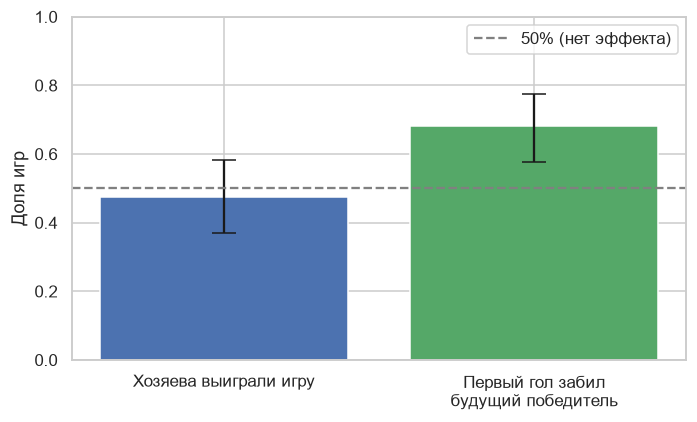

In [55]:
# Столбчатая диаграмма с 95% доверительными интервалами; пунктир — уровень 50% (случайный исход)
labels = ['Хозяева выиграли игру', 'Первый гол забил\nбудущий победитель']
vals = [k / n, k2 / n2]
errs = [[vals[0] - ci.low, vals[1] - ci2.low], [ci.high - vals[0], ci2.high - vals[1]]]   # длины «усов» вниз и вверх
plt.figure(figsize=(6.5, 4))
plt.bar(labels, vals, yerr=errs, capsize=8, color=['#4C72B0', '#55A868'])
plt.axhline(0.5, color='gray', linestyle='--', label='50% (нет эффекта)')
plt.ylim(0, 1)
plt.ylabel('Доля игр')
plt.legend()
plt.tight_layout()

**Ответ.**
- **Преимущества домашнего льда в этих данных нет.** Хозяева выиграли 39 из 82 игр (47.6 %, 95 % доверительный интервал [37.1 %; 58.2 %]); отличие от 50 % незначимо (p ≈ 0.74). Это не доказывает, что эффекта нет вообще (выборка небольшая), но в плей-офф 2026 он не обнаружен.
- **Первый гол действительно важен.** Команда, забившая первой, выиграла 56 из 82 игр (68.3 %, интервал [57.6 %; 77.4 %]), что значимо отличается от 50 % (p ≈ 0.001).
- Эффект растёт по ходу матча: лидер после 1-го периода выигрывал в 39 из 55 игр (≈ 71 %), после 2-го — в 46 из 57 (≈ 81 %). Спустя два периода счёт даёт уже большой, но не гарантированный шанс — камбэки возможны почти в каждой пятой игре.
- Оговорка: «первый гол» и «победа» частично связаны через общую причину — более сильная команда и забивает раньше, и чаще выигрывает, поэтому мы описываем связь, а не причинность.

## Итоги 

**Данные и общая картина.** Таблица содержит 29 710 событий 82 матчей плей-офф НХЛ 2025/2026. Сводная таблица игр проверена по числу голов в записях событий. В среднем в матче забивали около 5,9 шайбы (медиана 6, от 1 до 15 голов). Распределение скошено вправо, а «пилообразный» вид гистограммы объясняется чётностью разницы в счёте: все 22 игры с овертаймом закончились в один гол. Самые «сухие» матчи завершились со счётом 1 : 0 в овертайме, самый результативный — 15 голов.

**Броски и расстояние до ворот.** Расстояния до ворот рассчитаны для 7 266 бросков и совпали с контрольными значениями из условия. Основная масса бросков делается с небольшого расстояния, а вероятность гола быстро падает с удалением от ворот. Длинный хвост точных бросков со своей половины площадки — не ошибка данных. Он состоит из голов в пустые ворота в концовках матчей (17 голов) и дальних бросков, которые отбивает вратарь, нередко при игре в меньшинстве (168 бросков).

**Точность бросков.** Около 64 % незаблокированных бросков попадают в створ. Разброс этой доли между матчами лишь немного превышает случайный, а победители и проигравшие по ней не различаются (0,632 против 0,646, p ≈ 0,31). Устойчиво низкая доля — только у Pittsburgh Penguins (0,554). Остальные различия между командами, скорее всего, шум из-за малого числа игр.

**Броски и голы.** Между средним числом бросков в створ и средним числом голов за игру есть положительная умеренная связь (r ≈ 0,52, R² ≈ 0,27). Один дополнительный бросок за игру соответствует примерно +0,16 гола. Но это не единственный фактор: заметно отклоняются от прямой Vegas, Minnesota и Montréal (забивают больше «положенного»), а также Ottawa и Los Angeles (меньше). Самый «ударный» матч — Carolina Hurricanes – Ottawa Senators (3 : 2, два овертайма): 208 ударов по воротам.

**Игроки и вратари.** Больше всех голов забил Brett Howden (14), больше всех передач отдал Jack Eichel (20), лучший по очкам — Mitch Marner (29 = 10 + 19). По среднему числу бросков в створ за игру лидирует Jason Robertson (5,0), по силовым приёмам среди игроков с не менее чем 5 играми — Lawson Crouse (6,3). Хотя бы одну игру без пропущенных голов провели 8 вратарей (всего 12 таких выходов), в том числе несколько вышли на замену или были заменены по ходу матча.

**Собственное исследование.** В этих данных нет преимущества домашнего льда: хозяева выиграли 39 из 82 матчей (47,6 %, p ≈ 0,74). Зато первый гол важен: команда, забившая первой, выиграла 68 % матчей (p ≈ 0,001). Лидер после первого периода побеждал в ≈ 71 % случаев, после второго — в ≈ 81 %.

**Итог.** Результат матча плей-офф лишь отчасти определяется объёмом атаки (числом бросков в створ) и почти не зависит от того, какая доля незаблокированных бросков была точной. Заметную роль играют ранний гол, игра вратарей и конкретные игровые ситуации (меньшинство, замена вратаря, концовка при проигрыше). Все выводы основаны на 82 матчах, а у ряда команд на 4–7 играх, поэтому для многих различий статистическая надёжность ограничена.